In [1]:
!pip install catboost xgboost lightgbm gradio

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 35.2 MB/s  0:00:02


# Task 09 — Diabetes Patients (Classification)
**Goal:** predict whether a patient is diabetic. **Target:** `Class` (1 = Diabetic, 0 = Non-Diabetic). **Features:** Age, Gender, Blood_Sugar_Level, Creatinine, BMI, Urea, Cholesterol, HbA1c.

**Imbalance:** the dataset is imbalanced the other way round: about **91% Diabetic** and only **9% Non-Diabetic**. Accuracy alone is misleading (always saying "Diabetic" gives 91%), so we also look at **Precision, Recall, F1, Balanced Accuracy, ROC-AUC and PR-AUC**, and at the recall of the **minority class** (Non-Diabetic).

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from sklearn.preprocessing import StandardScaler, MinMaxScaler, LabelEncoder
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    balanced_accuracy_score,
    roc_auc_score,roc_curve,
    precision_recall_curve,average_precision_score
)
# Classification models
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

from sklearn.naive_bayes import GaussianNB

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier,
    VotingClassifier,
    StackingClassifier
)

from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier


## 1. Load the data

In [3]:
import os
path = 'dataset/diabetes_patients_10000_full.csv'
if not os.path.exists(path):          # e.g. file uploaded next to the notebook (Colab)
    path = 'diabetes_patients_10000_full.csv'
df = pd.read_csv(path)

In [4]:
df.head()

,Patient_ID,Age,Gender,Blood_Sugar_Level,Creatinine,BMI,Urea,Cholesterol,HbA1c,Class
0,1,60.0,Male,96.0,1.34,22.5,23.0,176.0,8.6,Diabetic
1,2,77.0,Male,241.0,1.02,19.0,28.0,209.0,7.5,Diabetic
2,3,21.0,Male,229.0,1.02,25.9,32.0,151.0,9.1,Diabetic
3,4,30.0,Female,177.0,0.88,22.1,36.0,176.0,5.1,Diabetic
4,5,26.0,Female,178.0,1.20,31.8,44.0,287.0,5.2,Diabetic


In [5]:
df.shape

(10000, 10)

In [6]:
df.columns

Index(['Patient_ID', 'Age', 'Gender', 'Blood_Sugar_Level', 'Creatinine', 'BMI',
       'Urea', 'Cholesterol', 'HbA1c', 'Class'],
      dtype='object')

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Patient_ID         10000 non-null  int64  
 1   Age                9986 non-null   float64
 2   Gender             9960 non-null   object 
 3   Blood_Sugar_Level  9947 non-null   float64
 4   Creatinine         9944 non-null   float64
 5   BMI                9949 non-null   float64
 6   Urea               9949 non-null   float64
 7   Cholesterol        9968 non-null   float64
 8   HbA1c              10000 non-null  float64
 9   Class              10000 non-null  object 
dtypes: float64(7), int64(1), object(2)
memory usage: 781.4+ KB


In [8]:
df.describe()

,Patient_ID,Age,Blood_Sugar_Level,Creatinine,BMI,Urea,Cholesterol,HbA1c
count,10000.00000,9986.000000,9947.000000,9944.000000,9949.000000,9949.000000,9968.000000,10000.000000
mean,5000.50000,49.957240,169.255454,1.100253,26.746959,35.121520,225.311196,7.503780
std,2886.89568,17.630097,46.059059,0.286964,4.787215,11.829985,43.806703,1.743745
min,1.00000,20.000000,90.000000,0.600000,18.500000,15.000000,150.000000,4.500000
25%,2500.75000,35.000000,130.000000,0.850000,22.600000,25.000000,187.000000,6.000000
50%,5000.50000,50.000000,169.000000,1.100000,26.700000,35.000000,225.000000,7.500000
75%,7500.25000,65.000000,209.000000,1.350000,31.000000,45.000000,263.000000,9.000000
max,10000.00000,80.000000,250.000000,1.600000,35.000000,55.000000,300.000000,10.500000


## 2. Data cleaning

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df = df.drop_duplicates()
if "Patient_ID" in df.columns:
    df = df.drop(columns="Patient_ID")

In [11]:
df.isnull().sum()

,0
Age,14
Gender,40
Blood_Sugar_Level,53
Creatinine,56
BMI,51
Urea,51
Cholesterol,32
HbA1c,0
Class,0


In [12]:
# a few values are missing in the features: they are filled AFTER the split (train data only)
missing = df.isnull().sum()
print(missing[missing > 0])

Age                  14
Gender               40
Blood_Sugar_Level    53
Creatinine           56
BMI                  51
Urea                 51
Cholesterol          32
dtype: int64


## 3. EDA (visualization)

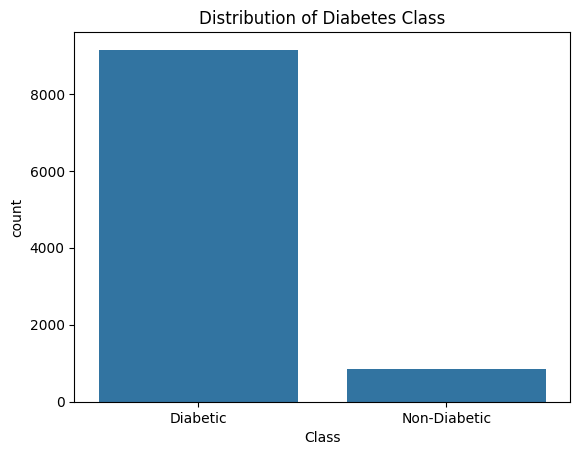

In [13]:
sns.countplot(x="Class", data=df)
plt.title("Distribution of Diabetes Class")
plt.show()

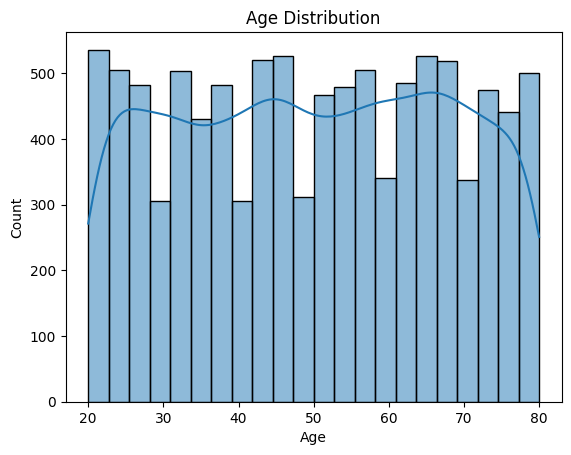

In [14]:
sns.histplot(df["Age"], kde=True)
plt.title("Age Distribution")
plt.show()

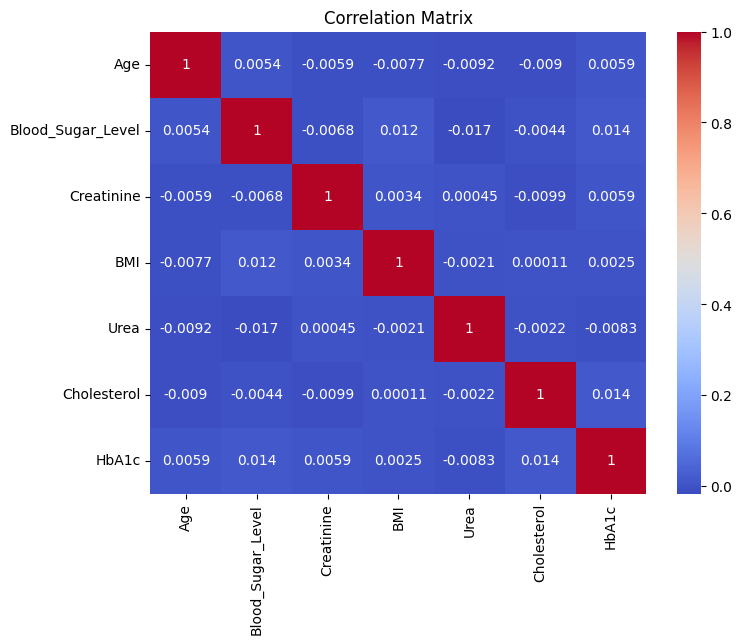

In [15]:
plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm")
plt.title("Correlation Matrix")
plt.show()

### Outliers (IQR rule)

In [16]:
for col in ['Age', 'Blood_Sugar_Level', 'Creatinine', 'BMI', 'Urea', 'Cholesterol', 'HbA1c']:
    q1, q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((df[col] < low) | (df[col] > high)).sum()
    print(f"{col}: {n_out} outliers ({n_out / len(df) * 100:.1f}%)  [min {df[col].min()}, max {df[col].max()}]")

Age: 0 outliers (0.0%)  [min 20.0, max 80.0]
Blood_Sugar_Level: 0 outliers (0.0%)  [min 90.0, max 250.0]
Creatinine: 0 outliers (0.0%)  [min 0.6, max 1.6]
BMI: 0 outliers (0.0%)  [min 18.5, max 35.0]
Urea: 0 outliers (0.0%)  [min 15.0, max 55.0]
Cholesterol: 0 outliers (0.0%)  [min 150.0, max 300.0]
HbA1c: 0 outliers (0.0%)  [min 4.5, max 10.5]


**Decision:** all the values are inside realistic medical ranges and the IQR rule finds no (or almost no) outliers, so **nothing is removed**. The numeric columns are scaled (fit on train only).

## 4. Encoding
Gender and the target are mapped to 0/1.

In [17]:
df["Gender"] = df["Gender"].map({"Female": 0, "Male": 1})
df["Class"] = df["Class"].map({"Non-Diabetic": 0, "Diabetic": 1})

## 5. Train / Test split
Stratified split: the percentage of each class stays the same in train and test.

In [18]:
X = df.drop(columns="Class")
y = df["Class"]

In [19]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

### Fill missing values (train data only, then applied to test) -> no data leakage

In [20]:
from sklearn.impute import SimpleImputer

X_train = X_train.copy()
X_test = X_test.copy()

num_impute_cols = ["Age", "Blood_Sugar_Level", "Creatinine", "BMI", "Urea", "Cholesterol", "HbA1c"]
imp_num = SimpleImputer(strategy='median')
X_train[num_impute_cols] = imp_num.fit_transform(X_train[num_impute_cols])
X_test[num_impute_cols] = imp_num.transform(X_test[num_impute_cols])

imp_gender = SimpleImputer(strategy='most_frequent')
X_train[['Gender']] = imp_gender.fit_transform(X_train[['Gender']])
X_test[['Gender']] = imp_gender.transform(X_test[['Gender']])

print("Missing values left:", X_train.isnull().sum().sum(), X_test.isnull().sum().sum())
print("Share of Diabetic in train / test:", round(y_train.mean(), 3), "/", round(y_test.mean(), 3))

Missing values left: 0 0
Share of Diabetic in train / test: 0.915 / 0.914


## 6. Scaling (fit on train only)

In [21]:
num_cols = ["Age", "Blood_Sugar_Level", "Creatinine", "BMI", "Urea", "Cholesterol", "HbA1c"]
scaler = StandardScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

## 7. Handling the imbalance
SMOTE and random under sampling are applied to the **train data only**; class weights are also tried. Models: Logistic Regression, KNN, Naive Bayes, SVM, Decision Tree.

In [22]:
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

rus = RandomUnderSampler(random_state=42)
X_train_rus, y_train_rus = rus.fit_resample(X_train, y_train)

In [23]:
results = []

In [24]:
for method_name, X_tr, y_tr in [("Normal Data", X_train, y_train), ("SMOTE Over Sampling", X_train_smote, y_train_smote), ("Random Under Sampling", X_train_rus, y_train_rus)]:
    log_model = LogisticRegression(max_iter=1000)
    log_model.fit(X_tr, y_tr)
    y_pred = log_model.predict(X_test)
    results.append({
        'Model': "Logistic Regression",
        'Method': method_name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1-Score': f1_score(y_test, y_pred, zero_division=0)
    })

In [25]:
log_cw = LogisticRegression(max_iter=1000, class_weight='balanced')
log_cw.fit(X_train, y_train)
y_pred = log_cw.predict(X_test)
results.append({
    'Model': "Logistic Regression",
    'Method': "Class Weight Balanced",
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred, zero_division=0),
    'Recall': recall_score(y_test, y_pred, zero_division=0),
    'F1-Score': f1_score(y_test, y_pred, zero_division=0)
})

In [26]:
for method_name, X_tr, y_tr in [("Normal Data", X_train, y_train), ("SMOTE Over Sampling", X_train_smote, y_train_smote), ("Random Under Sampling", X_train_rus, y_train_rus)]:
    knn_model = KNeighborsClassifier(n_neighbors=5)
    knn_model.fit(X_tr, y_tr)
    y_pred = knn_model.predict(X_test)
    results.append({
        'Model': "KNN",
        'Method': method_name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1-Score': f1_score(y_test, y_pred, zero_division=0)
    })

In [27]:
for method_name, X_tr, y_tr in [("Normal Data", X_train, y_train), ("SMOTE Over Sampling", X_train_smote, y_train_smote), ("Random Under Sampling", X_train_rus, y_train_rus)]:
    nb_model = GaussianNB()
    nb_model.fit(X_tr, y_tr)
    y_pred = nb_model.predict(X_test)
    results.append({
        'Model': "Naive Bayes",
        'Method': method_name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1-Score': f1_score(y_test, y_pred, zero_division=0)
    })

In [28]:
for method_name, X_tr, y_tr in [("Normal Data", X_train, y_train), ("SMOTE Over Sampling", X_train_smote, y_train_smote), ("Random Under Sampling", X_train_rus, y_train_rus)]:
    svm_model = SVC()
    svm_model.fit(X_tr, y_tr)
    y_pred = svm_model.predict(X_test)
    results.append({
        'Model': "SVM",
        'Method': method_name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1-Score': f1_score(y_test, y_pred, zero_division=0)
    })

In [29]:
svm_cw = SVC(class_weight='balanced')
svm_cw.fit(X_train, y_train)
y_pred = svm_cw.predict(X_test)
results.append({
    'Model': "SVM",
    'Method': "Class Weight Balanced",
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred, zero_division=0),
    'Recall': recall_score(y_test, y_pred, zero_division=0),
    'F1-Score': f1_score(y_test, y_pred, zero_division=0)
})

In [30]:
dt_params = dict(
    criterion='gini',
    random_state=100,
    max_depth=5,
    min_samples_split=10,
    min_samples_leaf=5,
    min_impurity_decrease=0.0,
    ccp_alpha=0.0
)

In [31]:
for method_name, X_tr, y_tr in [("Normal Data", X_train, y_train), ("SMOTE Over Sampling", X_train_smote, y_train_smote), ("Random Under Sampling", X_train_rus, y_train_rus)]:
    dt_model = DecisionTreeClassifier(**dt_params)
    dt_model.fit(X_tr, y_tr)
    y_pred = dt_model.predict(X_test)
    results.append({
        'Model': "Decision Tree",
        'Method': method_name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1-Score': f1_score(y_test, y_pred, zero_division=0)
    })

In [32]:
dt_cw = DecisionTreeClassifier(**dt_params, class_weight='balanced')
dt_cw.fit(X_train, y_train)
y_pred = dt_cw.predict(X_test)
results.append({
    'Model': "Decision Tree",
    'Method': "Class Weight Balanced",
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred, zero_division=0),
    'Recall': recall_score(y_test, y_pred, zero_division=0),
    'F1-Score': f1_score(y_test, y_pred, zero_division=0)
})

In [33]:
results_df = pd.DataFrame(results).set_index(['Model', 'Method'])
print(results_df.round(3))

                                           Accuracy  Precision  Recall  \
Model               Method                                               
Logistic Regression Normal Data               0.970      0.978   0.989   
                    SMOTE Over Sampling       0.949      0.995   0.949   
                    Random Under Sampling     0.931      0.996   0.928   
                    Class Weight Balanced     0.942      0.997   0.939   
KNN                 Normal Data               0.966      0.975   0.988   
                    SMOTE Over Sampling       0.932      0.998   0.928   
                    Random Under Sampling     0.858      0.999   0.845   
Naive Bayes         Normal Data               0.986      0.984   1.000   
                    SMOTE Over Sampling       0.976      0.999   0.974   
                    Random Under Sampling     0.963      0.999   0.960   
SVM                 Normal Data               0.978      0.984   0.992   
                    SMOTE Over Samplin

**Reading the table:** this table is evaluated on the test set to show how each balancing method changes Precision and Recall of the **Diabetic** class. SMOTE / under-sampling / class weights usually lower the Diabetic precision a little and help the minority (Non-Diabetic) class. Because the data are almost perfectly separable (see below), the differences are small.

In [34]:
from sklearn.tree import DecisionTreeClassifier

dt_feat_model = DecisionTreeClassifier(random_state=42, max_depth=5)
dt_feat_model.fit(X_train, y_train)

importances = pd.Series(dt_feat_model.feature_importances_, index=X.columns)
importances = importances.sort_values(ascending=False)

selected_features = importances.index[:10]
print("Top 10 Important Features:", selected_features.tolist())

selected_features = importances.nlargest(10)
print("Decision Tree Selected Features (Scores):", selected_features.tolist())

Top 10 Important Features: ['Blood_Sugar_Level', 'HbA1c', 'Age', 'Gender', 'Creatinine', 'BMI', 'Urea', 'Cholesterol']
Decision Tree Selected Features (Scores): [0.7306579865889125, 0.2689497306734827, 0.0003922827376048195, 0.0, 0.0, 0.0, 0.0, 0.0]


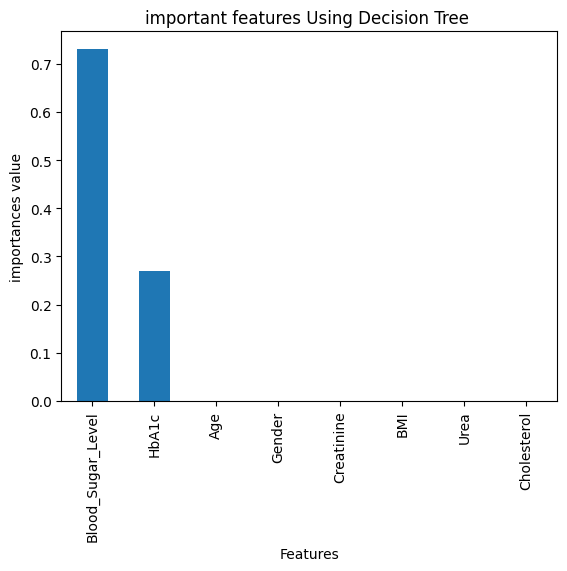

In [35]:
importances.plot(kind='bar')
plt.title("important features Using Decision Tree ")
plt.xlabel("Features")
plt.ylabel("importances value")
plt.show()

In [36]:
from sklearn.model_selection import GridSearchCV

grid_params = {'C': [0.1, 1, 10], 'kernel': ['linear', 'rbf']}
grid = GridSearchCV(estimator=SVC(), param_grid=grid_params, cv=5, scoring='f1')
grid.fit(X_train, y_train)

print("Best Parameters:", grid.best_params_)
print("Best CV F1 Score:", grid.best_score_)

Best Parameters: {'C': 10, 'kernel': 'rbf'}
Best CV F1 Score: 0.9915991484766693


In [37]:
best_model = grid.best_estimator_

**Note:** this first tuning of the SVM used F1 of the Diabetic class and cross-validation on the train data. The final model selection below is done again for **all** models.

## 8. All the models
All models of the track are trained on the prepared data and evaluated on the test set (confusion matrix, classification report, ROC curve, PR curve).

In [38]:
models = {

    # Linear
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=1),

    # Distance-based
    "KNN": KNeighborsClassifier(n_neighbors=5),

    # SVM
    "SVC": SVC(probability=True, random_state=1),

    # Tree
    "Decision Tree": DecisionTreeClassifier(random_state=1),

    # Naive Bayes
    "Naive Bayes": GaussianNB(),

    # Bagging Based
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=1),
    "Extra Trees": ExtraTreesClassifier(n_estimators=100, random_state=1),

    # Boosting
    "AdaBoost": AdaBoostClassifier(random_state=1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=1),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(random_state=1),

    # External Boosting Libraries
    "XGBoost": XGBClassifier(eval_metric='logloss', random_state=1),
    "CatBoost": CatBoostClassifier(verbose=0, random_state=1),
    "LightGBM": LGBMClassifier(random_state=1)
}

  0%|          | 0/13 [00:00<?, ?it/s]


Confusion Matrix:
 [[ 131   40]
 [  20 1809]]


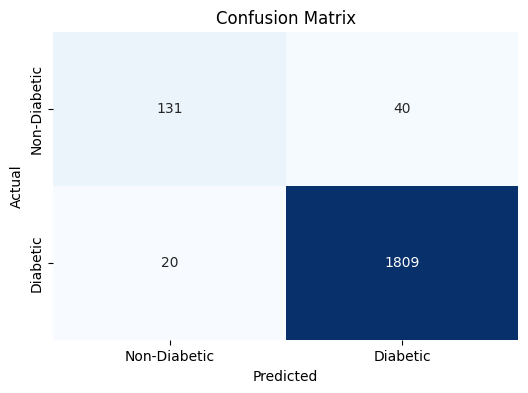


Classification Report:

              precision    recall  f1-score   support

Non-Diabetic       0.87      0.77      0.81       171
    Diabetic       0.98      0.99      0.98      1829

    accuracy                           0.97      2000
   macro avg       0.92      0.88      0.90      2000
weighted avg       0.97      0.97      0.97      2000

ROC-AUC: 0.9903056346899689


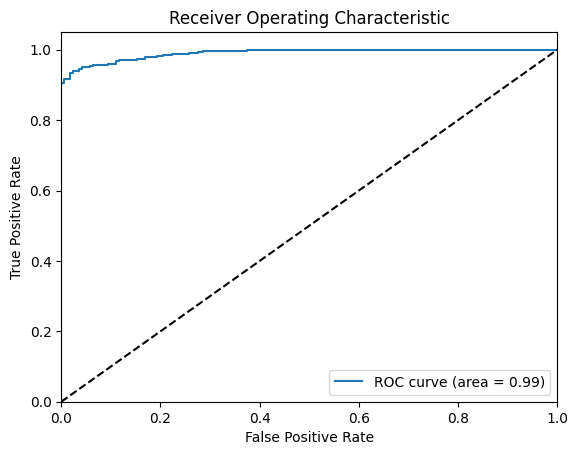

PR AUC: 0.999090551883218


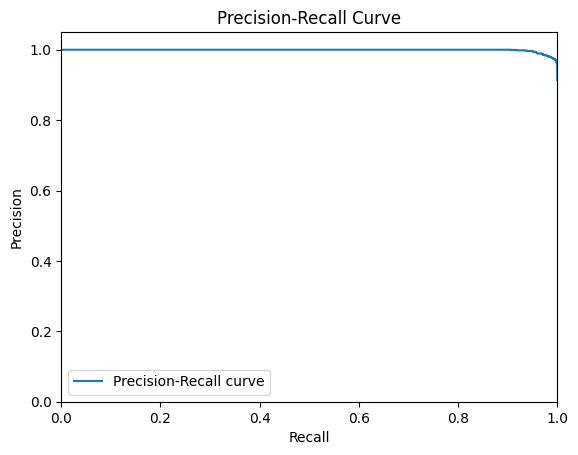

  8%|▊         | 1/13 [00:01<00:22,  1.86s/it]


Confusion Matrix:
 [[ 124   47]
 [  22 1807]]


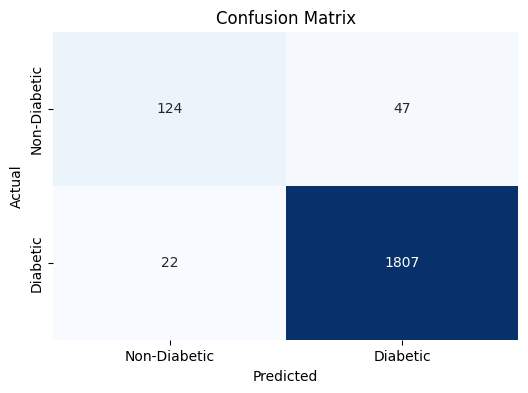


Classification Report:

              precision    recall  f1-score   support

Non-Diabetic       0.85      0.73      0.78       171
    Diabetic       0.97      0.99      0.98      1829

    accuracy                           0.97      2000
   macro avg       0.91      0.86      0.88      2000
weighted avg       0.96      0.97      0.96      2000

ROC-AUC: 0.9798886682717365


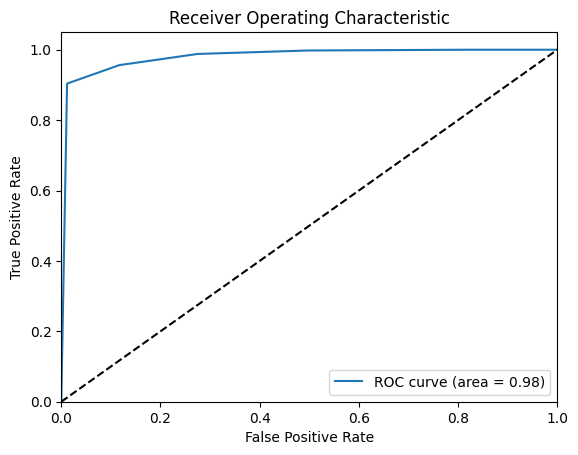

PR AUC: 0.9969170410590283


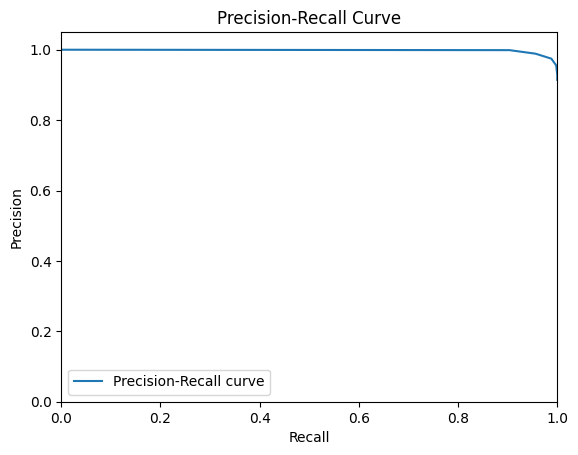

 15%|█▌        | 2/13 [00:04<00:27,  2.49s/it]


Confusion Matrix:
 [[ 141   30]
 [  15 1814]]


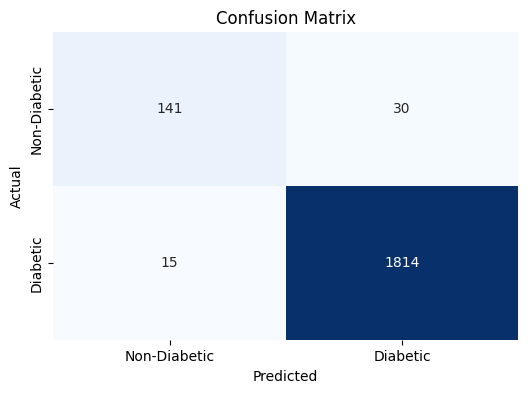


Classification Report:

              precision    recall  f1-score   support

Non-Diabetic       0.90      0.82      0.86       171
    Diabetic       0.98      0.99      0.99      1829

    accuracy                           0.98      2000
   macro avg       0.94      0.91      0.93      2000
weighted avg       0.98      0.98      0.98      2000

ROC-AUC: 0.9944973605875451


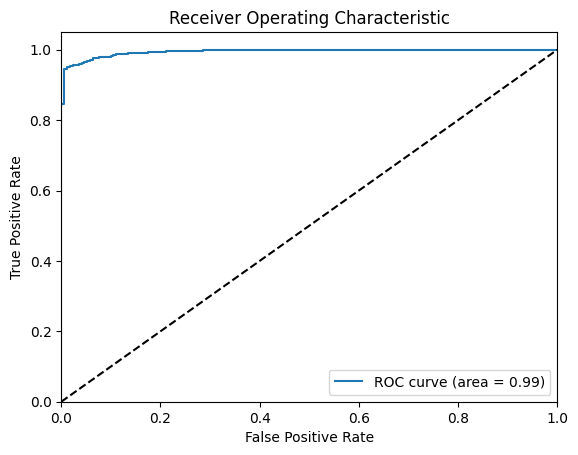

PR AUC: 0.9994786570620044


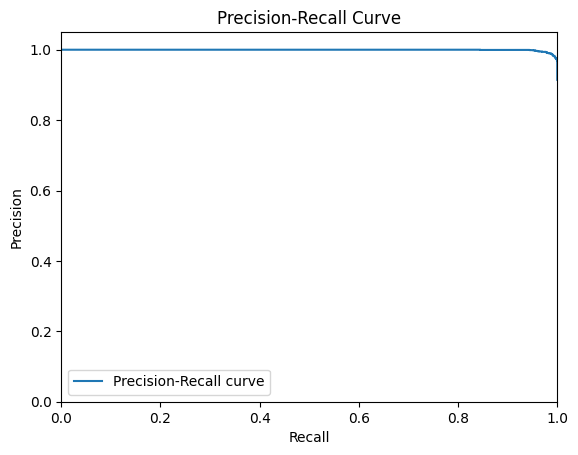

 23%|██▎       | 3/13 [00:08<00:29,  2.90s/it]


Confusion Matrix:
 [[ 170    1]
 [   1 1828]]


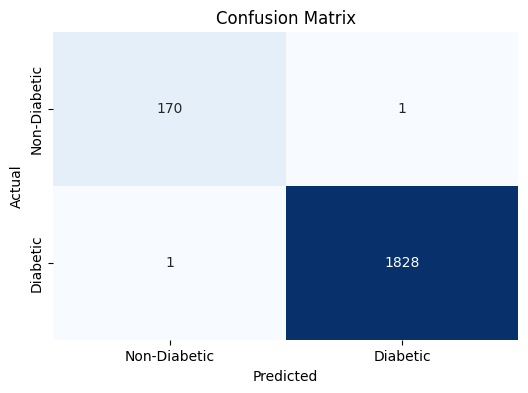


Classification Report:

              precision    recall  f1-score   support

Non-Diabetic       0.99      0.99      0.99       171
    Diabetic       1.00      1.00      1.00      1829

    accuracy                           1.00      2000
   macro avg       1.00      1.00      1.00      2000
weighted avg       1.00      1.00      1.00      2000

ROC-AUC: 0.99680264996371


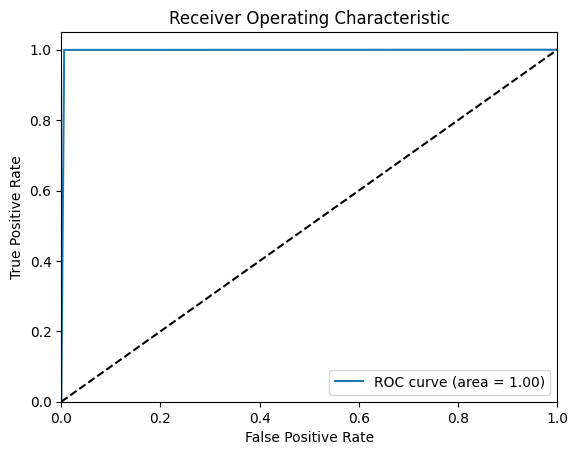

PR AUC: 0.9994068052197136


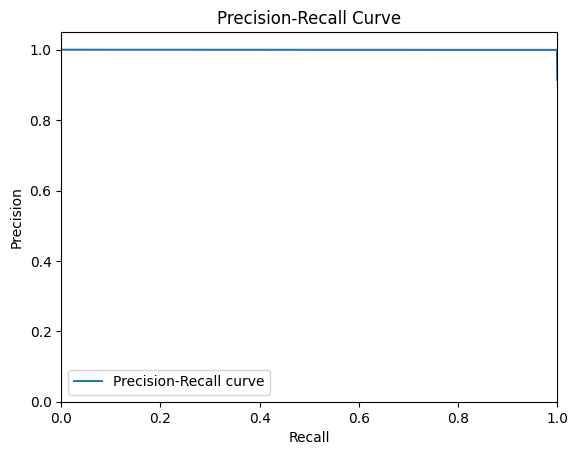

 31%|███       | 4/13 [00:08<00:17,  1.93s/it]


Confusion Matrix:
 [[ 142   29]
 [   0 1829]]


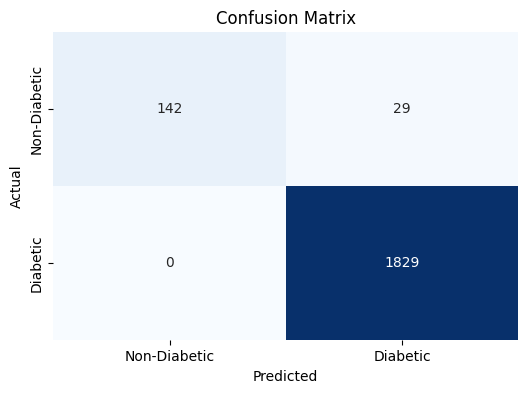


Classification Report:

              precision    recall  f1-score   support

Non-Diabetic       1.00      0.83      0.91       171
    Diabetic       0.98      1.00      0.99      1829

    accuracy                           0.99      2000
   macro avg       0.99      0.92      0.95      2000
weighted avg       0.99      0.99      0.98      2000

ROC-AUC: 0.9985388110334155


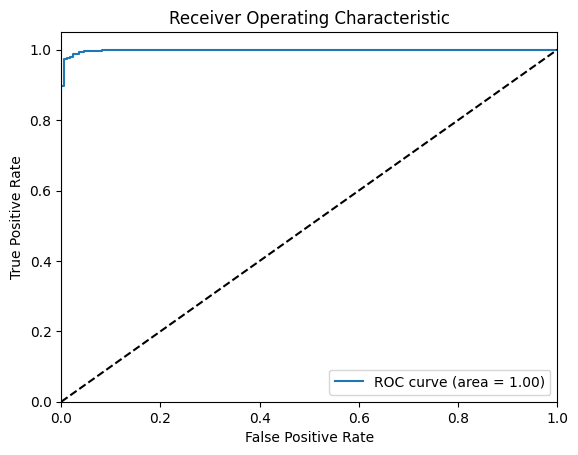

PR AUC: 0.9998603680670685


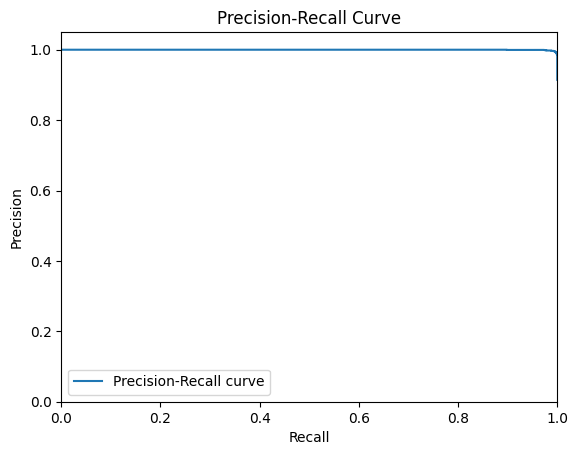

 38%|███▊      | 5/13 [00:09<00:11,  1.40s/it]


Confusion Matrix:
 [[ 170    1]
 [   0 1829]]


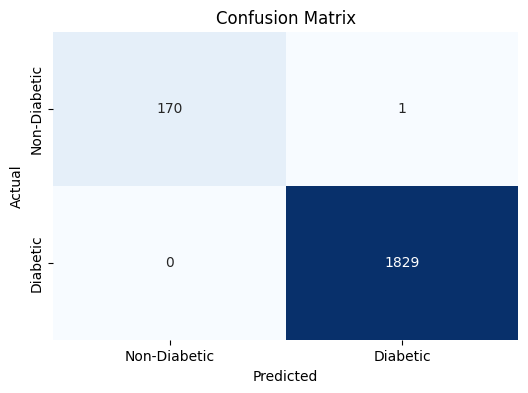


Classification Report:

              precision    recall  f1-score   support

Non-Diabetic       1.00      0.99      1.00       171
    Diabetic       1.00      1.00      1.00      1829

    accuracy                           1.00      2000
   macro avg       1.00      1.00      1.00      2000
weighted avg       1.00      1.00      1.00      2000

ROC-AUC: 1.0


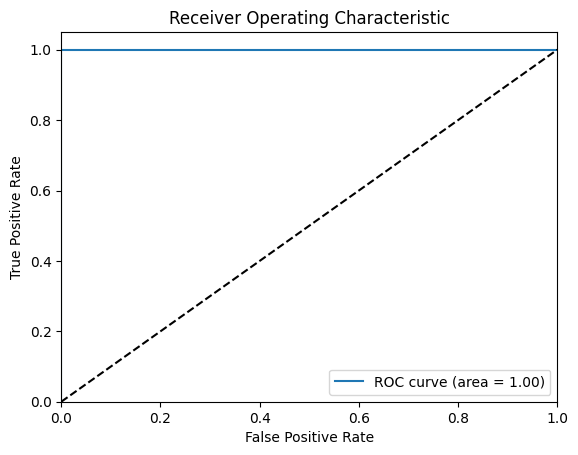

PR AUC: 1.0


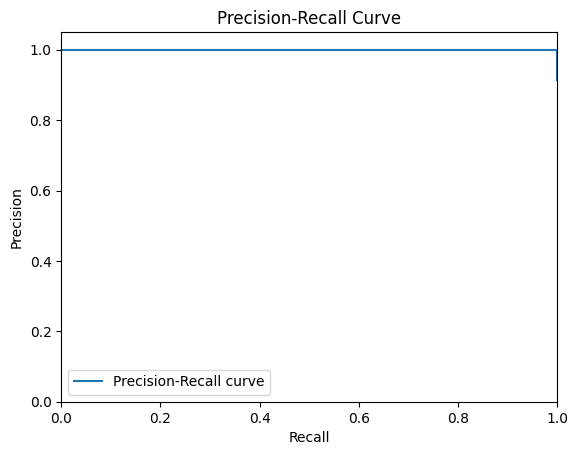

 46%|████▌     | 6/13 [00:10<00:08,  1.27s/it]


Confusion Matrix:
 [[ 149   22]
 [   2 1827]]


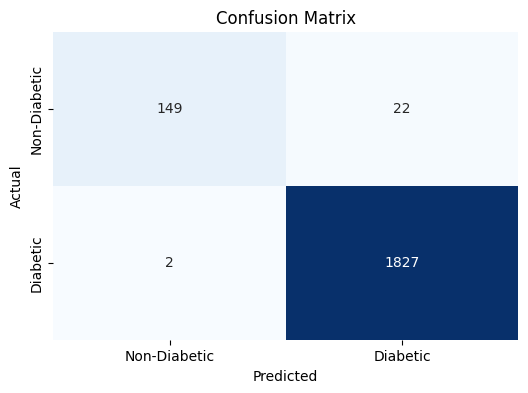


Classification Report:

              precision    recall  f1-score   support

Non-Diabetic       0.99      0.87      0.93       171
    Diabetic       0.99      1.00      0.99      1829

    accuracy                           0.99      2000
   macro avg       0.99      0.94      0.96      2000
weighted avg       0.99      0.99      0.99      2000

ROC-AUC: 0.999171886340601


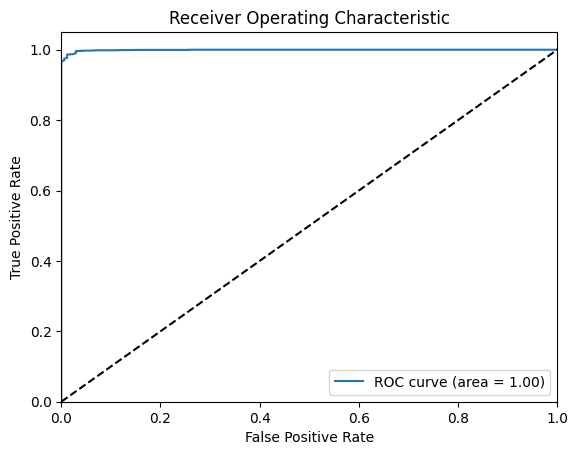

PR AUC: 0.9999181329550949


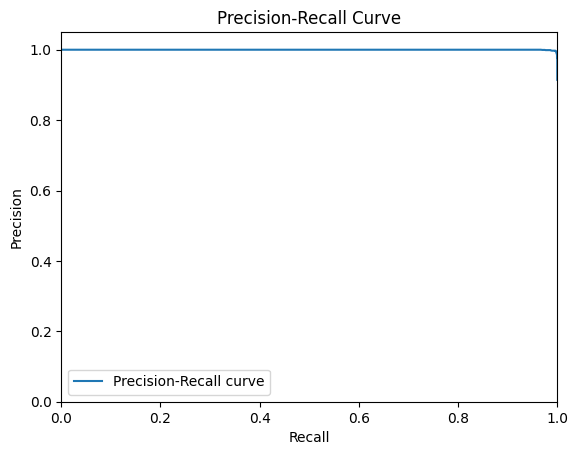

 54%|█████▍    | 7/13 [00:11<00:07,  1.19s/it]


Confusion Matrix:
 [[ 170    1]
 [   0 1829]]


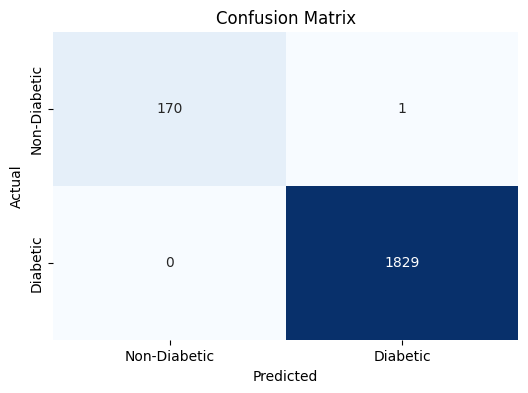


Classification Report:

              precision    recall  f1-score   support

Non-Diabetic       1.00      0.99      1.00       171
    Diabetic       1.00      1.00      1.00      1829

    accuracy                           1.00      2000
   macro avg       1.00      1.00      1.00      2000
weighted avg       1.00      1.00      1.00      2000

ROC-AUC: 0.9999984013249819


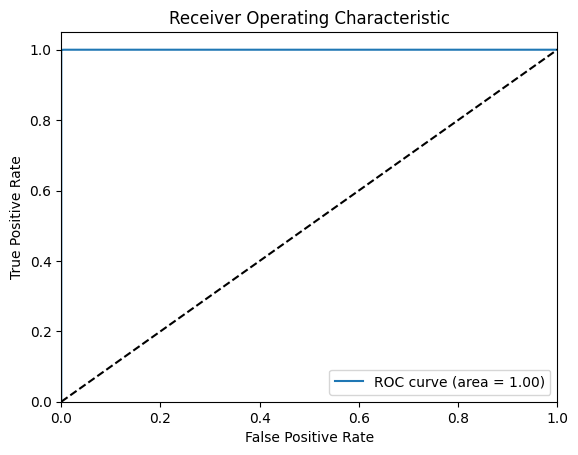

PR AUC: 0.9999997012312261


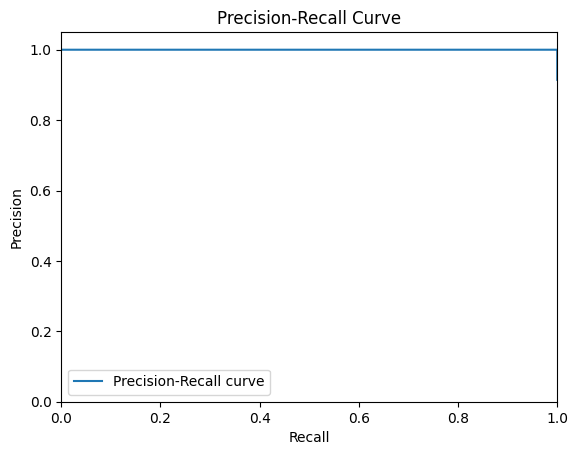

 62%|██████▏   | 8/13 [00:12<00:05,  1.09s/it]


Confusion Matrix:
 [[ 170    1]
 [   0 1829]]


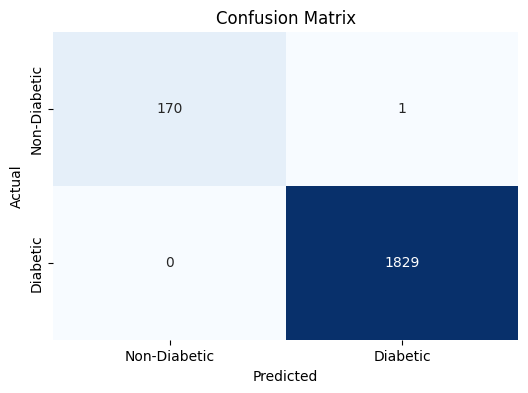


Classification Report:

              precision    recall  f1-score   support

Non-Diabetic       1.00      0.99      1.00       171
    Diabetic       1.00      1.00      1.00      1829

    accuracy                           1.00      2000
   macro avg       1.00      1.00      1.00      2000
weighted avg       1.00      1.00      1.00      2000

ROC-AUC: 1.0


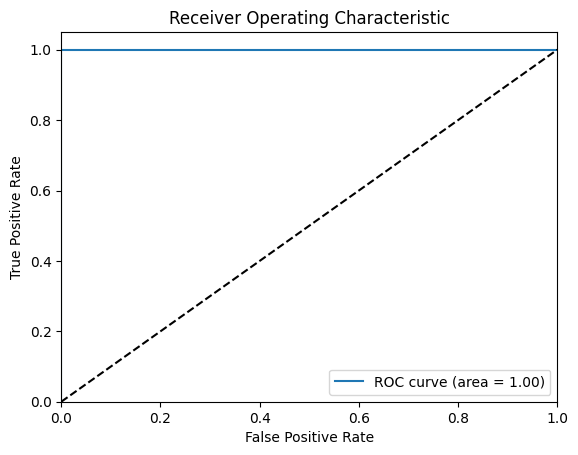

PR AUC: 1.0


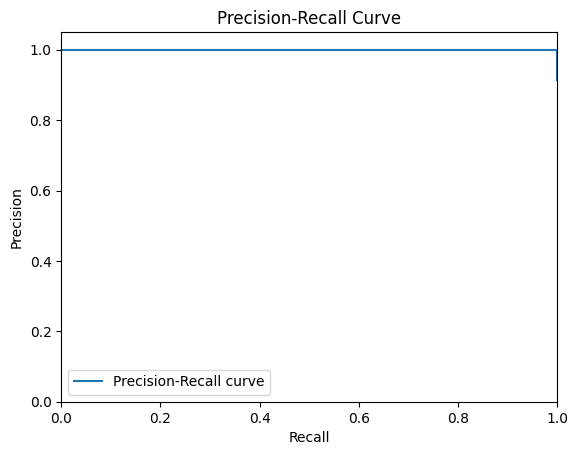

 69%|██████▉   | 9/13 [00:13<00:05,  1.25s/it]


Confusion Matrix:
 [[ 170    1]
 [   0 1829]]


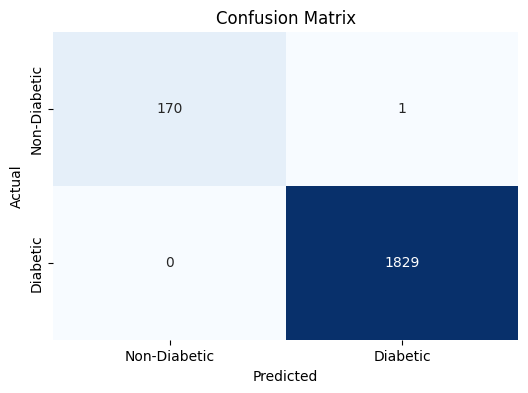


Classification Report:

              precision    recall  f1-score   support

Non-Diabetic       1.00      0.99      1.00       171
    Diabetic       1.00      1.00      1.00      1829

    accuracy                           1.00      2000
   macro avg       1.00      1.00      1.00      2000
weighted avg       1.00      1.00      1.00      2000

ROC-AUC: 1.0


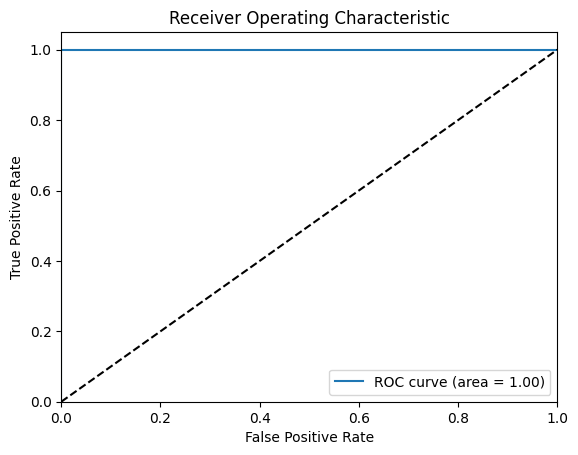

PR AUC: 1.0


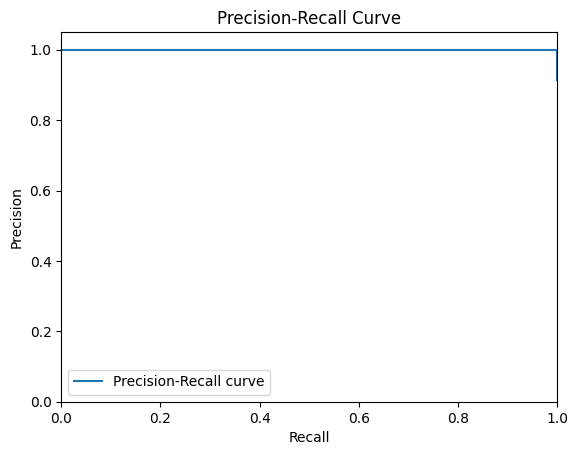

 77%|███████▋  | 10/13 [00:14<00:03,  1.15s/it]


Confusion Matrix:
 [[ 170    1]
 [   0 1829]]


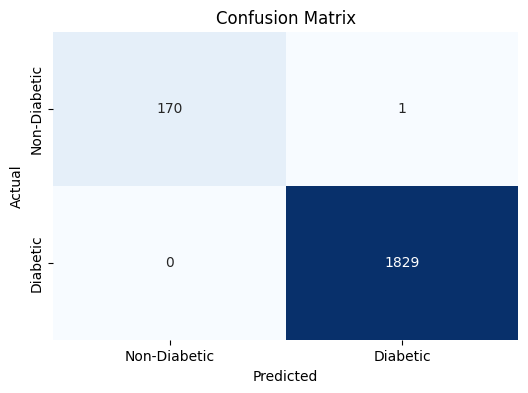


Classification Report:

              precision    recall  f1-score   support

Non-Diabetic       1.00      0.99      1.00       171
    Diabetic       1.00      1.00      1.00      1829

    accuracy                           1.00      2000
   macro avg       1.00      1.00      1.00      2000
weighted avg       1.00      1.00      1.00      2000

ROC-AUC: 1.0


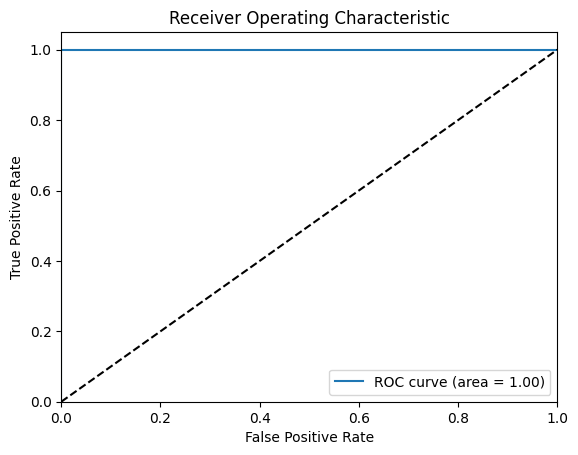

PR AUC: 1.0


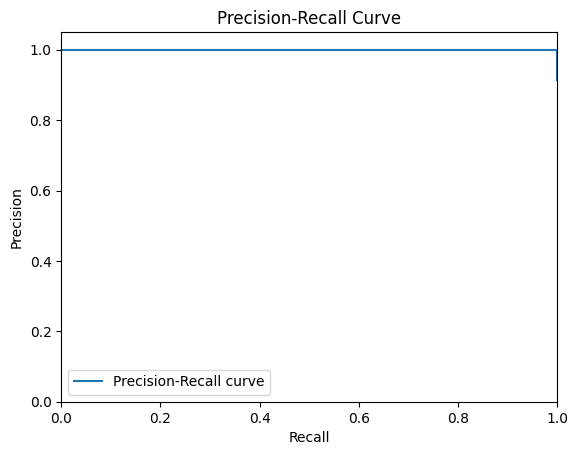

 85%|████████▍ | 11/13 [00:15<00:02,  1.12s/it]


Confusion Matrix:
 [[ 170    1]
 [   0 1829]]


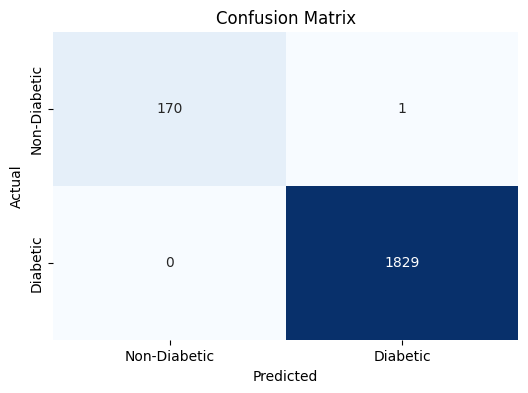


Classification Report:

              precision    recall  f1-score   support

Non-Diabetic       1.00      0.99      1.00       171
    Diabetic       1.00      1.00      1.00      1829

    accuracy                           1.00      2000
   macro avg       1.00      1.00      1.00      2000
weighted avg       1.00      1.00      1.00      2000

ROC-AUC: 1.0


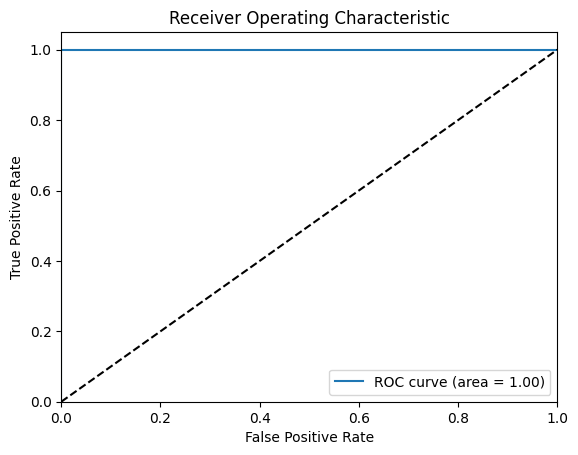

PR AUC: 1.0


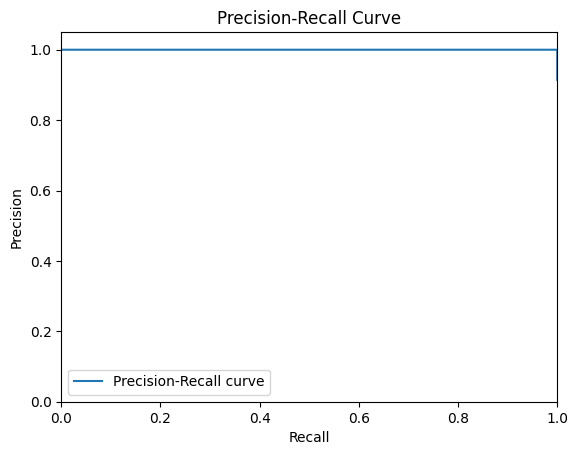

 92%|█████████▏| 12/13 [00:20<00:02,  2.32s/it]

[LightGBM] [Info] Number of positive: 7317, number of negative: 683
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.002237 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 752
[LightGBM] [Info] Number of data points in the train set: 8000, number of used features: 8
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.914625 -> initscore=2.371461
[LightGBM] [Info] Start training from score 2.371461
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best 

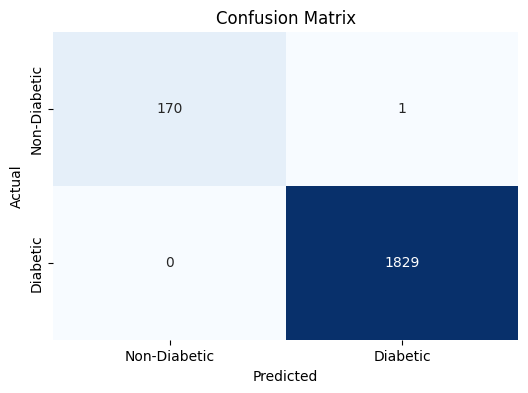


Classification Report:

              precision    recall  f1-score   support

Non-Diabetic       1.00      0.99      1.00       171
    Diabetic       1.00      1.00      1.00      1829

    accuracy                           1.00      2000
   macro avg       1.00      1.00      1.00      2000
weighted avg       1.00      1.00      1.00      2000

ROC-AUC: 1.0


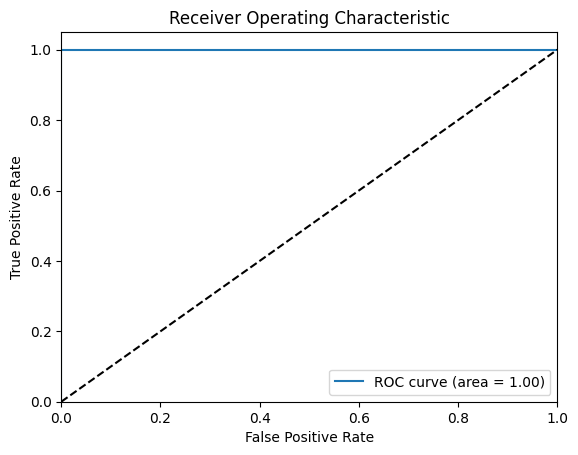

PR AUC: 1.0000000000000002


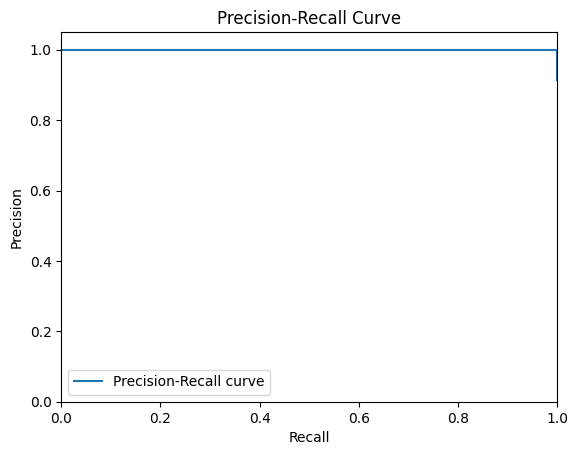

100%|██████████| 13/13 [00:21<00:00,  1.64s/it]


In [39]:
results = {}

for name, model in tqdm(models.items()):
    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred  = model.predict(X_test)



    cm = confusion_matrix(y_test, test_pred)
    print("\nConfusion Matrix:\n", cm)

    plt.figure(figsize=(6,4))
    sns.heatmap(cm,annot=True,fmt="d",cmap='Blues',cbar=False,
                xticklabels=['Non-Diabetic','Diabetic']
                ,yticklabels=['Non-Diabetic','Diabetic'])
    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    plt.title('Confusion Matrix')
    plt.show()

    # Full classification report
    print("\nClassification Report:\n")
    print(classification_report(y_test, test_pred,target_names=['Non-Diabetic','Diabetic'],zero_division=0))

    y_pred_prob = model.predict_proba(X_test)[:, 1]
    roc_auc = roc_auc_score(y_test, y_pred_prob)
    print("ROC-AUC:", roc_auc)

    # ROC curve
    fpr, tpr, roc_thresholds = roc_curve(y_test, y_pred_prob)
    plt.figure()
    plt.plot(fpr, tpr, label='ROC curve (area = {:.2f})'.format(roc_auc))
    plt.plot([0, 1], [0, 1], 'k--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Receiver Operating Characteristic')
    plt.legend(loc="lower right")
    plt.show()

    pr_auc = average_precision_score(y_test, y_pred_prob)
    print("PR AUC:", pr_auc)

    precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, y_pred_prob)
    plt.figure()
    plt.plot(recall_vals, precision_vals, label='Precision-Recall curve')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title('Precision-Recall Curve')
    plt.legend(loc="lower left")
    plt.show()

    results[name] = {
        "Train Accuracy": accuracy_score(y_train, train_pred),
        "Test Accuracy": accuracy_score(y_test, test_pred),
        "Train Precision": precision_score(y_train, train_pred),
        "Test Precision": precision_score(y_test, test_pred),
        "Train Recall": recall_score(y_train, train_pred),
        "Test Recall": recall_score(y_test, test_pred),
        "Train F1 Score": f1_score(y_train, train_pred),
        "Test F1 Score": f1_score(y_test, test_pred),
        "Train Balanced Accuracy": balanced_accuracy_score(y_train, train_pred),
        "Test Balanced Accuracy": balanced_accuracy_score(y_test, test_pred),
        "ROC-AUC": roc_auc,
        "PR AUC": pr_auc

    }


Confusion Matrix:
 [[ 170    1]
 [   0 1829]]


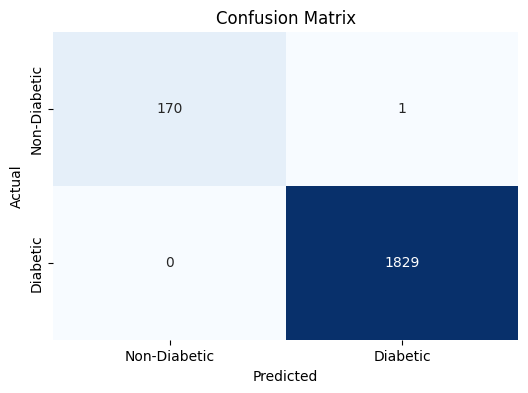


Classification Report:

              precision    recall  f1-score   support

Non-Diabetic       1.00      0.99      1.00       171
    Diabetic       1.00      1.00      1.00      1829

    accuracy                           1.00      2000
   macro avg       1.00      1.00      1.00      2000
weighted avg       1.00      1.00      1.00      2000

ROC-AUC: 0.9998145536978953


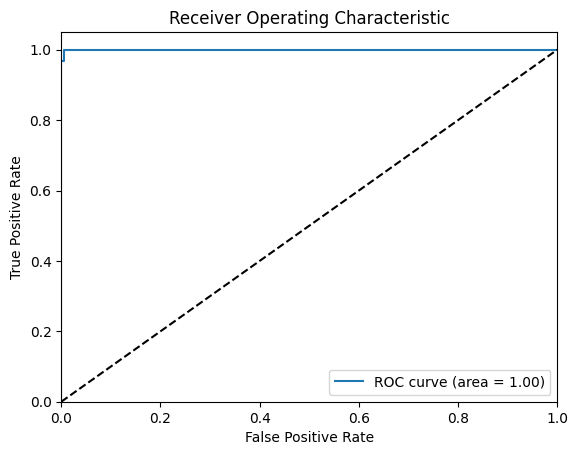

PR AUC: 0.999982395749958


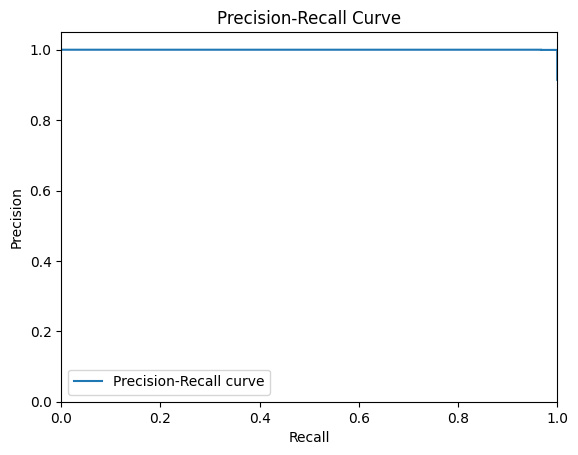

In [40]:
voting_model = VotingClassifier(
    estimators=[
        ("lr", models["Logistic Regression"]),
        ("rf", models["Random Forest"]),
        ("nb", models["Naive Bayes"]),
        ("xgb", models["XGBoost"]),
    ],
    voting="soft" # voting='hard' / voting='soft', weights=[2, 1, 2,1]
)

voting_model.fit(X_train, y_train)
voting_train_pred = voting_model.predict(X_train)
voting_test_pred = voting_model.predict(X_test)


cm = confusion_matrix(y_test, voting_test_pred)
print("\nConfusion Matrix:\n", cm)

plt.figure(figsize=(6,4))
sns.heatmap(cm,annot=True,fmt="d",cmap='Blues',cbar=False,
             xticklabels=['Non-Diabetic','Diabetic']
            ,yticklabels=['Non-Diabetic','Diabetic'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix')
plt.show()

# Full classification report
print("\nClassification Report:\n")
print(classification_report(y_test, voting_test_pred,target_names=['Non-Diabetic','Diabetic'],zero_division=0))

y_pred_prob = voting_model.predict_proba(X_test)[:, 1]
roc_auc = roc_auc_score(y_test, y_pred_prob)
print("ROC-AUC:", roc_auc)

# ROC curve
fpr, tpr, roc_thresholds = roc_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(fpr, tpr, label='ROC curve (area = {:.2f})'.format(roc_auc))
plt.plot([0, 1], [0, 1], 'k--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

pr_auc = average_precision_score(y_test, y_pred_prob)
print("PR AUC:", pr_auc)

precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(recall_vals, precision_vals, label='Precision-Recall curve')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend(loc="lower left")
plt.show()

results["Voting Classifier"] = {
    "Train Accuracy": accuracy_score(y_train, voting_train_pred),
    "Test Accuracy": accuracy_score(y_test, voting_test_pred),
    "Train Precision": precision_score(y_train, voting_train_pred),
    "Test Precision": precision_score(y_test, voting_test_pred),
    "Train Recall": recall_score(y_train, voting_train_pred),
    "Test Recall": recall_score(y_test, voting_test_pred),
    "Train F1 Score": f1_score(y_train, voting_train_pred),
    "Test F1 Score": f1_score(y_test, voting_test_pred),
    "Train Balanced Accuracy": balanced_accuracy_score(y_train, voting_train_pred),
    "Test Balanced Accuracy": balanced_accuracy_score(y_test, voting_test_pred),
    "ROC-AUC": roc_auc,
    "PR AUC": pr_auc
}


Confusion Matrix:
 [[ 170    1]
 [   0 1829]]


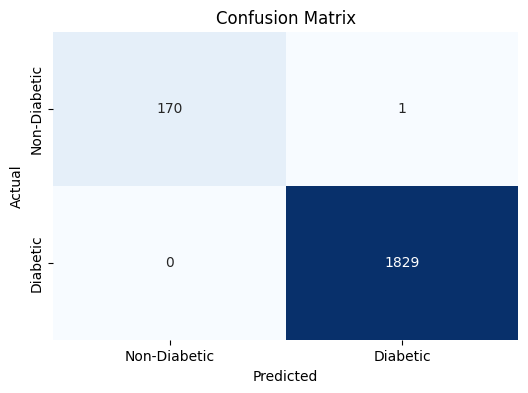


Classification Report:

              precision    recall  f1-score   support

Non-Diabetic       1.00      0.99      1.00       171
    Diabetic       1.00      1.00      1.00      1829

    accuracy                           1.00      2000
   macro avg       1.00      1.00      1.00      2000
weighted avg       1.00      1.00      1.00      2000

ROC-AUC: 1.0


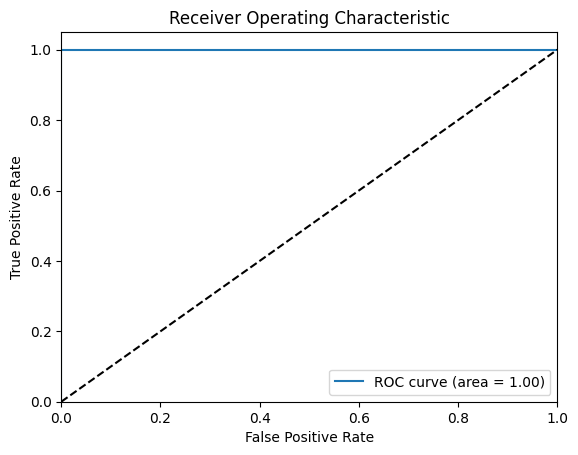

PR AUC: 1.0


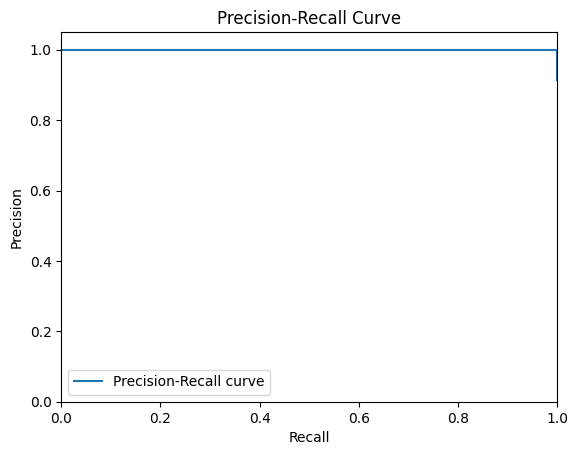

In [41]:
stack_auto = StackingClassifier(
    estimators=[
        ("lr", models["Logistic Regression"]),
        ("rf", models["Random Forest"]),
        ("nb", models["Naive Bayes"]),
        ("lgbm", models["LightGBM"]),


    ],
    final_estimator=XGBClassifier(eval_metric='logloss', random_state=1),
    stack_method="predict_proba",   # best for classification usually
    n_jobs=-1
)

# Train
stack_auto.fit(X_train, y_train)

# Predictions
stack_auto_train_pred = stack_auto.predict(X_train)
stack_auto_test_pred  = stack_auto.predict(X_test)

cm = confusion_matrix(y_test, stack_auto_test_pred)
print("\nConfusion Matrix:\n", cm)

plt.figure(figsize=(6,4))
sns.heatmap(cm,annot=True,fmt="d",cmap='Blues',cbar=False,
             xticklabels=['Non-Diabetic','Diabetic']
            ,yticklabels=['Non-Diabetic','Diabetic'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix')
plt.show()

# Full classification report
print("\nClassification Report:\n")
print(classification_report(y_test, stack_auto_test_pred,target_names=['Non-Diabetic','Diabetic'],zero_division=0))

y_pred_prob = stack_auto.predict_proba(X_test)[:, 1]
roc_auc = roc_auc_score(y_test, y_pred_prob)
print("ROC-AUC:", roc_auc)

# ROC curve
fpr, tpr, roc_thresholds = roc_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(fpr, tpr, label='ROC curve (area = {:.2f})'.format(roc_auc))
plt.plot([0, 1], [0, 1], 'k--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

pr_auc = average_precision_score(y_test, y_pred_prob)
print("PR AUC:", pr_auc)

precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(recall_vals, precision_vals, label='Precision-Recall curve')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend(loc="lower left")
plt.show()

results["Stacking Classifier "] = {
    "Train Accuracy": accuracy_score(y_train, stack_auto_train_pred),
    "Test Accuracy": accuracy_score(y_test, stack_auto_test_pred),
    "Train Precision": precision_score(y_train, stack_auto_train_pred),
    "Test Precision": precision_score(y_test, stack_auto_test_pred),
    "Train Recall": recall_score(y_train, stack_auto_train_pred),
    "Test Recall": recall_score(y_test, stack_auto_test_pred),
    "Train F1 Score": f1_score(y_train, stack_auto_train_pred),
    "Test F1 Score": f1_score(y_test, stack_auto_test_pred),
    "Train Balanced Accuracy": balanced_accuracy_score(y_train, stack_auto_train_pred),
    "Test Balanced Accuracy": balanced_accuracy_score(y_test, stack_auto_test_pred),
    "ROC-AUC": roc_auc,
    "PR AUC": pr_auc
}

In [42]:
results_df = pd.DataFrame(results).T
results_df = results_df.sort_values(by="Test F1 Score", ascending=False)

In [43]:
results_df

,Train Accuracy,Test Accuracy,Train Precision,Test Precision,Train Recall,Test Recall,Train F1 Score,Test F1 Score,Train Balanced Accuracy,Test Balanced Accuracy,ROC-AUC,PR AUC
Random Forest,1.000000,0.9995,1.000000,0.999454,1.000000,1.000000,1.000000,0.999727,1.000000,0.997076,1.000000,1.000000
LightGBM,1.000000,0.9995,1.000000,0.999454,1.000000,1.000000,1.000000,0.999727,1.000000,0.997076,1.000000,1.000000
CatBoost,1.000000,0.9995,1.000000,0.999454,1.000000,1.000000,1.000000,0.999727,1.000000,0.997076,1.000000,1.000000
XGBoost,1.000000,0.9995,1.000000,0.999454,1.000000,1.000000,1.000000,0.999727,1.000000,0.997076,1.000000,1.000000
Hist Gradient Boosting,1.000000,0.9995,1.000000,0.999454,1.000000,1.000000,1.000000,0.999727,1.000000,0.997076,1.000000,1.000000
Gradient Boosting,1.000000,0.9995,1.000000,0.999454,1.000000,1.000000,1.000000,0.999727,1.000000,0.997076,1.000000,1.000000
AdaBoost,0.999750,0.9995,0.999727,0.999454,1.000000,1.000000,0.999863,0.999727,0.998536,0.997076,0.999998,1.000000
Voting Classifier,0.999750,0.9995,0.999727,0.999454,1.000000,1.000000,0.999863,0.999727,0.998536,0.997076,0.999815,0.999982
Stacking Classifier,1.000000,0.9995,1.000000,0.999454,1.000000,1.000000,1.000000,0.999727,1.000000,0.997076,1.000000,1.000000
Decision Tree,1.000000,0.9990,1.000000,0.999453,1.000000,0.999453,1.000000,0.999453,1.000000,0.996803,0.996803,0.999407


<Axes: >

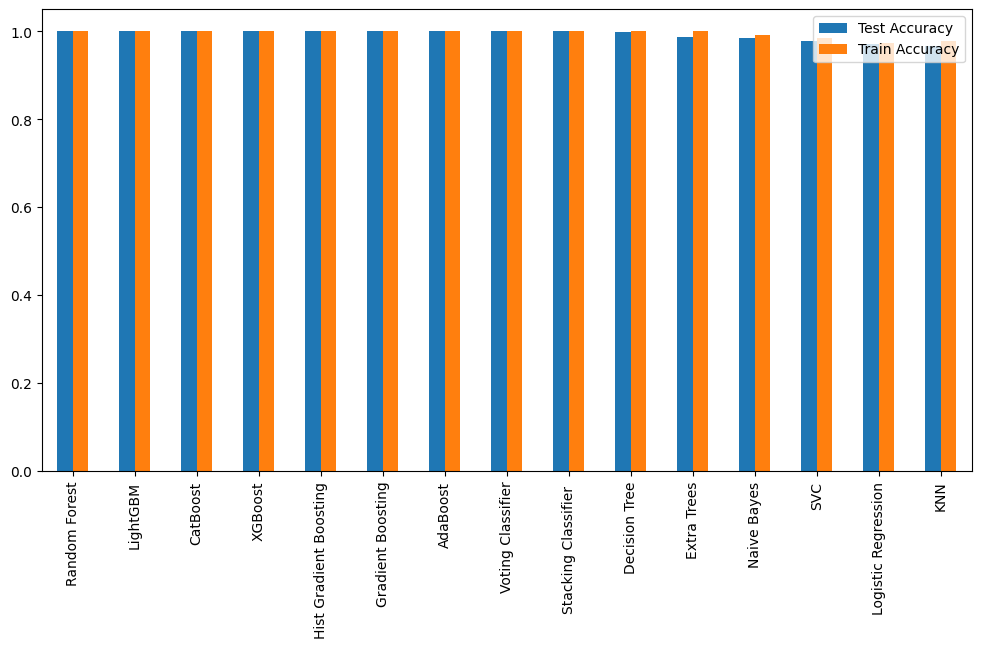

In [44]:
results_df[["Test Accuracy", "Train Accuracy"]].plot.bar(figsize=(12,6))

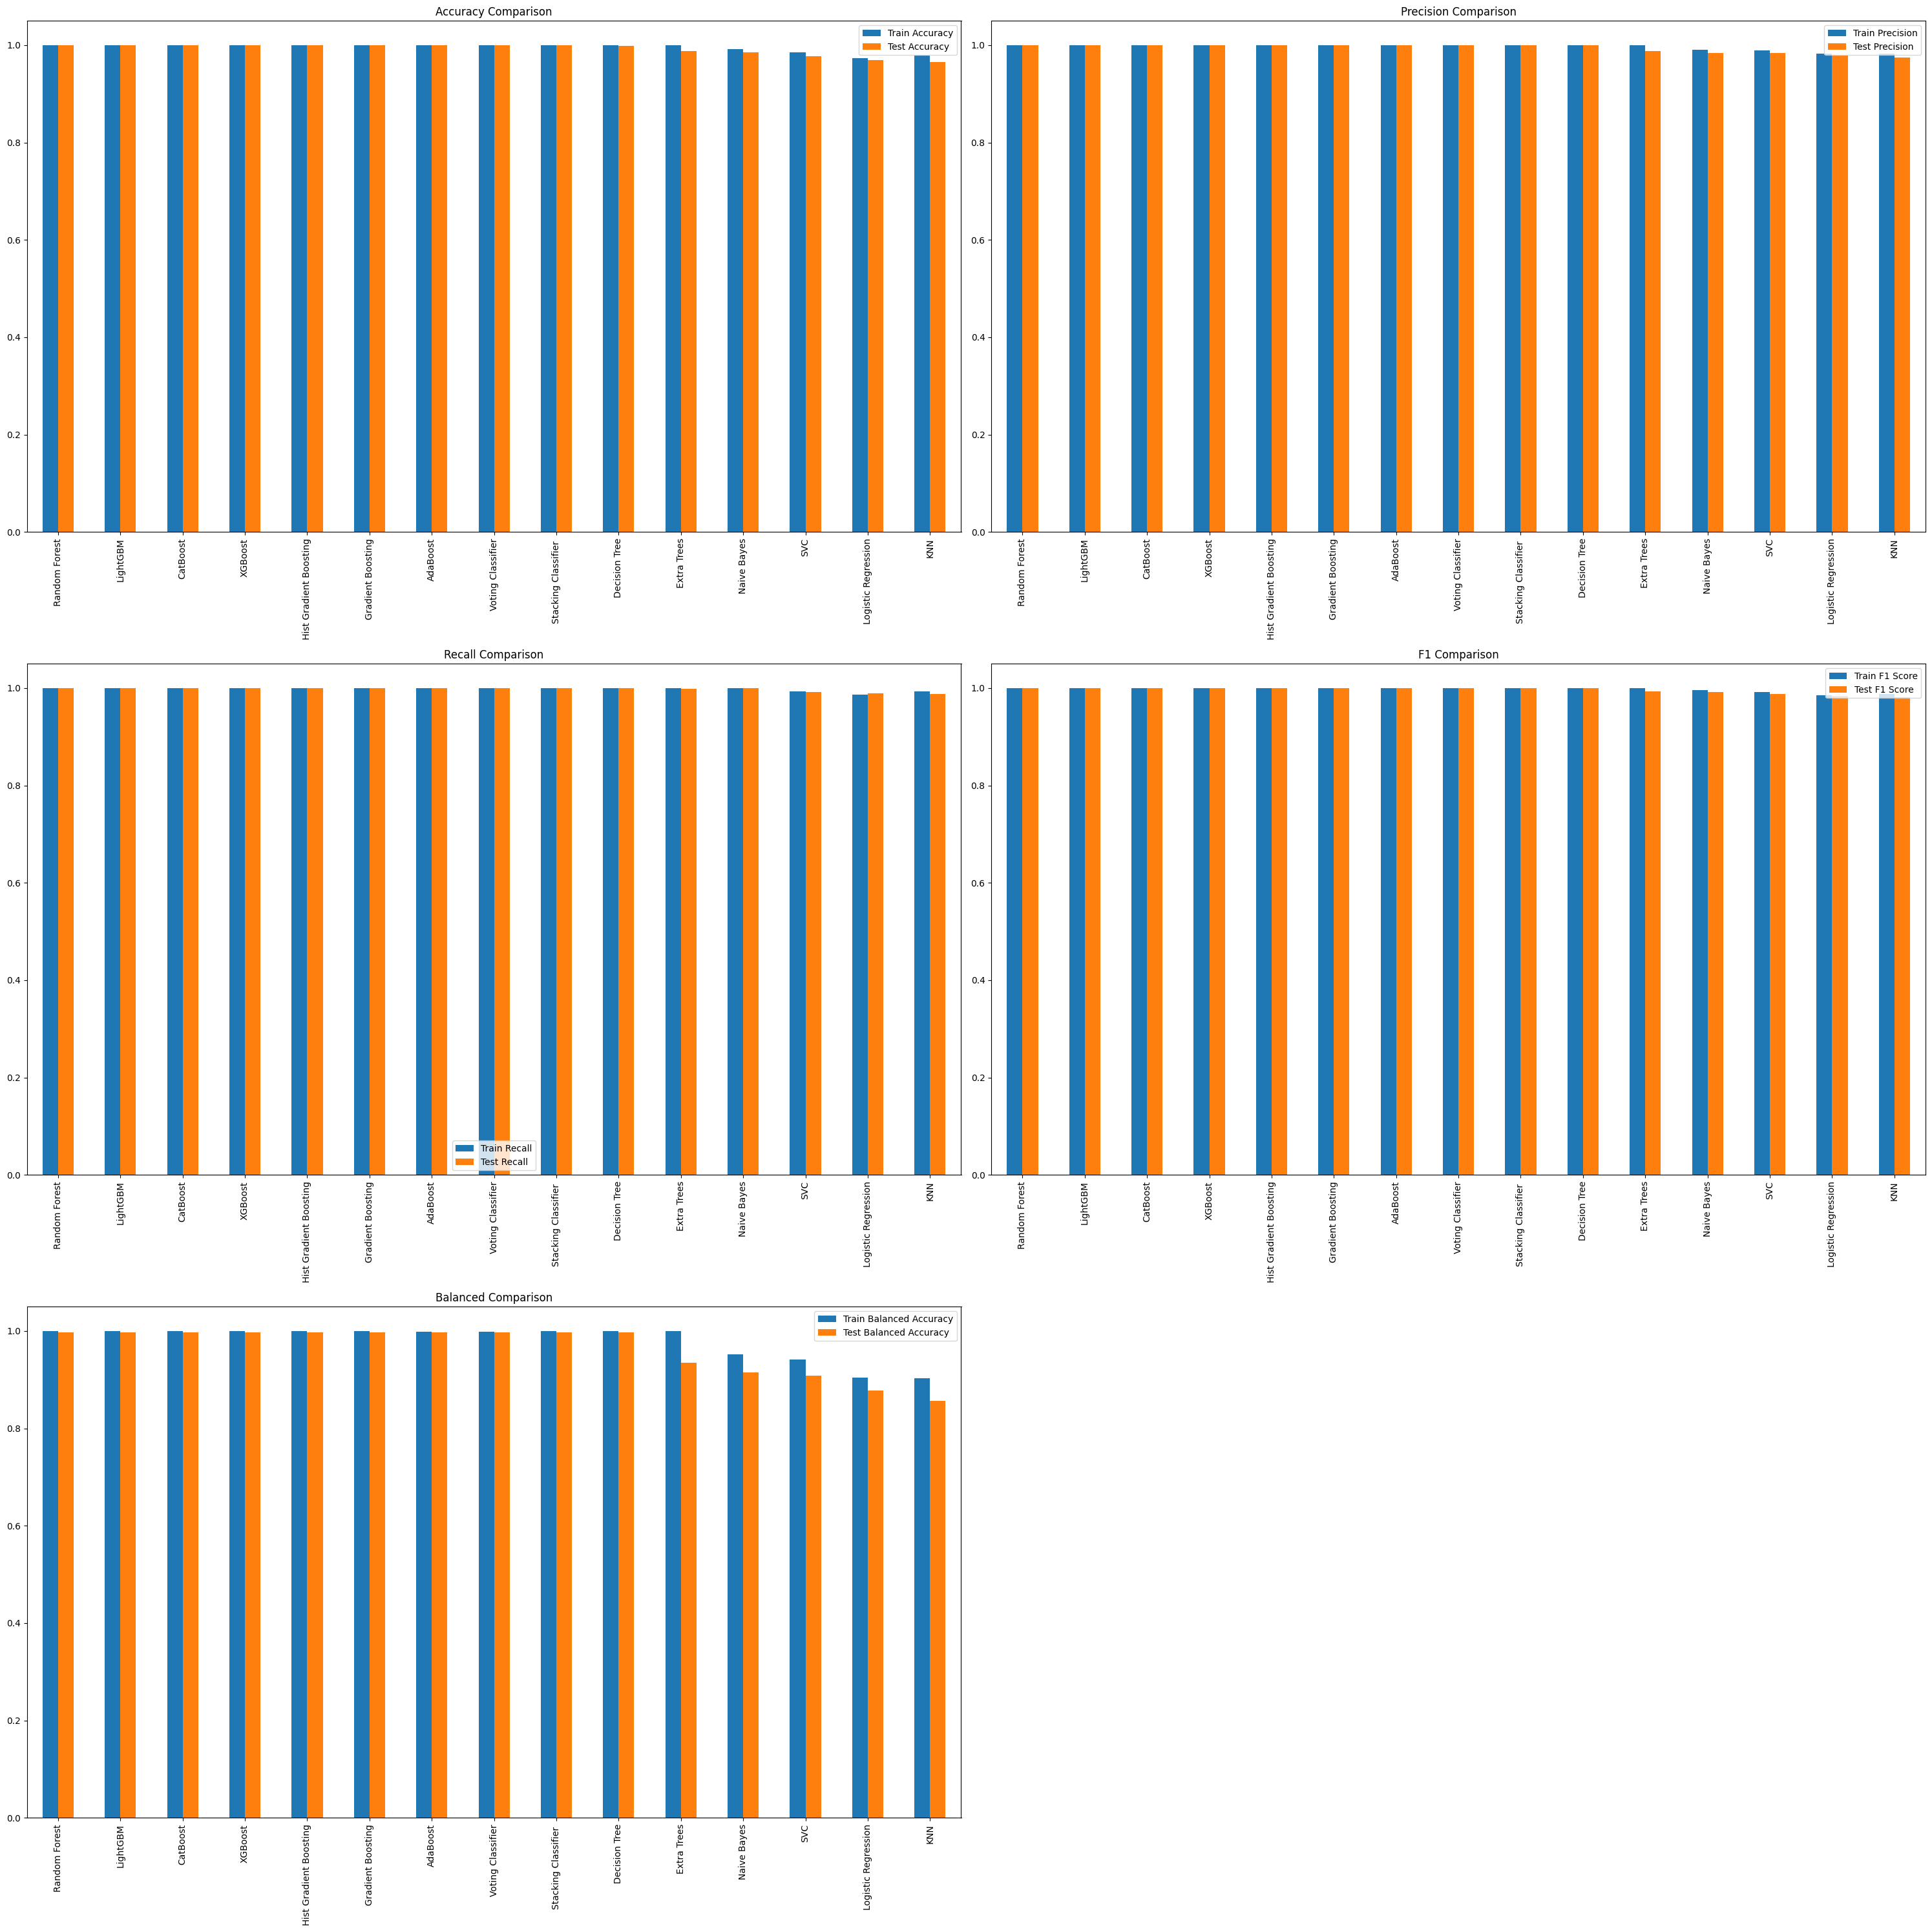

In [45]:
cols = [
    ['Train Accuracy', 'Test Accuracy'],
    ['Train Precision', 'Test Precision'],
    ['Train Recall', 'Test Recall'],
    ['Train F1 Score', 'Test F1 Score'],
    ["Train Balanced Accuracy", "Test Balanced Accuracy"]
]

plt.figure(figsize=(30,30))

for i, col in enumerate(cols):
    ax = plt.subplot(3, 2, i+1)
    results_df[col].plot.bar(ax=ax)
    ax.set_title(col[0].split(" ")[1] + ' Comparison')

plt.tight_layout()
plt.show()

**Note:** this table uses the test set to show how each model behaves with the default threshold. To **choose** and **tune** the model we use cross-validation on the training data only (next sections).

## 9. Model comparison with Cross-Validation (train data only)
5-fold stratified cross-validation on the training data. Metrics: **ROC-AUC**, **macro F1** (both classes count equally) and **balanced accuracy**. (`SVC` is used without `probability=True` inside the CV only to save time.)

In [46]:
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict, GridSearchCV
from sklearn.base import clone

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_rows = {}
for name, model in tqdm(models.items()):
    m = SVC(random_state=1) if name == "SVC" else model
    cv = cross_validate(m, X_train, y_train, cv=skf, n_jobs=-1,
                        scoring={'roc_auc': 'roc_auc', 'f1_macro': 'f1_macro', 'bal_acc': 'balanced_accuracy'})
    cv_rows[name] = {'CV ROC-AUC': cv['test_roc_auc'].mean(), 'CV F1 macro': cv['test_f1_macro'].mean(),
                     'CV Balanced Acc': cv['test_bal_acc'].mean()}

cv_df = pd.DataFrame(cv_rows).T.sort_values(['CV ROC-AUC', 'CV F1 macro'], ascending=False)
cv_df

100%|██████████| 13/13 [00:33<00:00,  2.56s/it]


,CV ROC-AUC,CV F1 macro,CV Balanced Acc
LightGBM,0.999994,0.999196,0.998535
Hist Gradient Boosting,0.999993,0.999196,0.998535
Gradient Boosting,0.999986,0.999196,0.998535
AdaBoost,0.999985,0.999196,0.998535
CatBoost,0.999972,0.999196,0.998535
XGBoost,0.999938,0.999196,0.998535
Random Forest,0.999739,0.999196,0.998535
Extra Trees,0.999245,0.962158,0.935494
Naive Bayes,0.999069,0.971496,0.950887
Decision Tree,0.998466,0.998799,0.998466


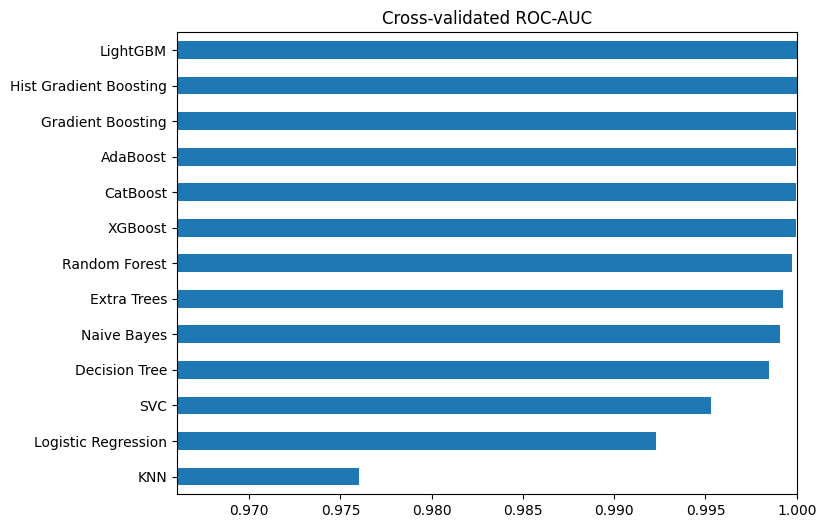

In [47]:
cv_df['CV ROC-AUC'].sort_values().plot.barh(figsize=(8, 6))
plt.title('Cross-validated ROC-AUC')
plt.xlim(cv_df['CV ROC-AUC'].min() - 0.01, 1.0)
plt.show()

## 10. GridSearchCV on the best 3 models
The top 3 models of the cross-validation comparison are tuned with `GridSearchCV` (5-fold, metric ROC-AUC, training data only). `class_weight` is part of the grid when the model supports it.

In [48]:
param_grids = {
    'Logistic Regression': {'C': [0.01, 0.1, 1, 10], 'class_weight': [None, 'balanced']},
    'KNN': {'n_neighbors': [5, 11, 21, 41], 'weights': ['uniform', 'distance']},
    'SVC': {'C': [0.5, 1, 5], 'class_weight': [None, 'balanced']},
    'Decision Tree': {'max_depth': [3, 5, 8], 'min_samples_leaf': [5, 20, 50], 'class_weight': [None, 'balanced']},
    'Naive Bayes': {'var_smoothing': [1e-9, 1e-7, 1e-5, 1e-3]},
    'Random Forest': {'max_depth': [5, 10, None], 'min_samples_leaf': [1, 5, 10], 'class_weight': [None, 'balanced_subsample']},
    'Extra Trees': {'max_depth': [5, 10, None], 'min_samples_leaf': [1, 5, 10], 'class_weight': [None, 'balanced_subsample']},
    'AdaBoost': {'n_estimators': [50, 100, 200], 'learning_rate': [0.1, 0.5, 1.0]},
    'Gradient Boosting': {'n_estimators': [100, 200], 'learning_rate': [0.05, 0.1], 'max_depth': [2, 3]},
    'Hist Gradient Boosting': {'learning_rate': [0.03, 0.1], 'max_depth': [3, None], 'class_weight': [None, 'balanced']},
    'XGBoost': {'n_estimators': [100, 300], 'max_depth': [2, 3], 'learning_rate': [0.03, 0.1]},
    'CatBoost': {'iterations': [300, 600], 'depth': [4, 6], 'learning_rate': [0.03, 0.1]},
    'LightGBM': {'n_estimators': [100, 300], 'num_leaves': [8, 15], 'learning_rate': [0.03, 0.1]},
}

top3 = cv_df.head(3).index.tolist()
print("Models to tune:", top3)

tuned = {}
summary = []
for name in top3:
    m = SVC(random_state=1) if name == "SVC" else models[name]
    grid = GridSearchCV(m, param_grids[name], cv=skf, scoring='roc_auc', n_jobs=-1)
    grid.fit(X_train, y_train)
    tuned[name] = grid
    print(f"\n{name}")
    print("  best_params_:", grid.best_params_)
    print("  best_score_ :", round(grid.best_score_, 5))
    summary.append([name, cv_df.loc[name, 'CV ROC-AUC'], grid.best_score_])

tuning_df = pd.DataFrame(summary, columns=['Model', 'Before tuning (CV ROC-AUC)', 'After tuning (best_score_)']).set_index('Model')
tuning_df

Models to tune: ['LightGBM', 'Hist Gradient Boosting', 'Gradient Boosting']
[LightGBM] [Info] Number of positive: 7317, number of negative: 683
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001470 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 752
[LightGBM] [Info] Number of data points in the train set: 8000, number of used features: 8
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.914625 -> initscore=2.371461
[LightGBM] [Info] Start training from score 2.371461
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best

,Before tuning (CV ROC-AUC),After tuning (best_score_)
Model,,
LightGBM,0.999994,0.999995
Hist Gradient Boosting,0.999993,0.999993
Gradient Boosting,0.999986,0.999986


**Why these parameters:** `C` and `max_depth` / leaf size control the complexity (overfitting vs underfitting); `class_weight='balanced'` gives more importance to the minority class (Non-Diabetic); `learning_rate` and the number of trees trade off in boosting; `n_neighbors` controls the smoothness of KNN. When the models are almost perfect, the tuning gives very small differences.

## 11. Final model and decision threshold
The best tuned model (highest `best_score_`) is refitted on the train data. With an imbalanced target the default threshold 0.5 is not always the best, so the threshold is chosen on **cross-validated predictions of the training data**: the one that maximizes `recall(Diabetic) + recall(Non-Diabetic) - 1` (Youden's J, it treats both classes equally). The test set is not used for this.

In [49]:
best_name = tuning_df['After tuning (best_score_)'].idxmax()
best_model = clone(tuned[best_name].best_estimator_)
print("Best model:", best_name, tuned[best_name].best_params_)

oof_proba = cross_val_predict(best_model, X_train, y_train, cv=skf, method='predict_proba', n_jobs=-1)[:, 1]
fpr_tr, tpr_tr, thr_tr = roc_curve(y_train, oof_proba)
best_thr = float(thr_tr[np.argmax(tpr_tr - fpr_tr)])
print("Chosen threshold:", round(best_thr, 3))

best_model.fit(X_train, y_train)

Best model: LightGBM {'learning_rate': 0.1, 'n_estimators': 300, 'num_leaves': 15}
Chosen threshold: 0.973
[LightGBM] [Info] Number of positive: 7317, number of negative: 683
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000226 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 752
[LightGBM] [Info] Number of data points in the train set: 8000, number of used features: 8
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.914625 -> initscore=2.371461
[LightGBM] [Info] Start training from score 2.371461
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with

LGBMClassifier(n_estimators=300, num_leaves=15, random_state=1)

## 12. Final evaluation on the test set (used once)

--- Classification Report (tuned threshold) ---
              precision    recall  f1-score   support

Non-Diabetic       1.00      0.99      1.00       171
    Diabetic       1.00      1.00      1.00      1829

    accuracy                           1.00      2000
   macro avg       1.00      1.00      1.00      2000
weighted avg       1.00      1.00      1.00      2000

Accuracy: 0.9995 | Balanced accuracy: 0.9971
ROC-AUC: 1.0 | PR-AUC Diabetic: 1.0 (random 0.91 ) | PR-AUC Non-Diabetic: 1.0 (random 0.09 )


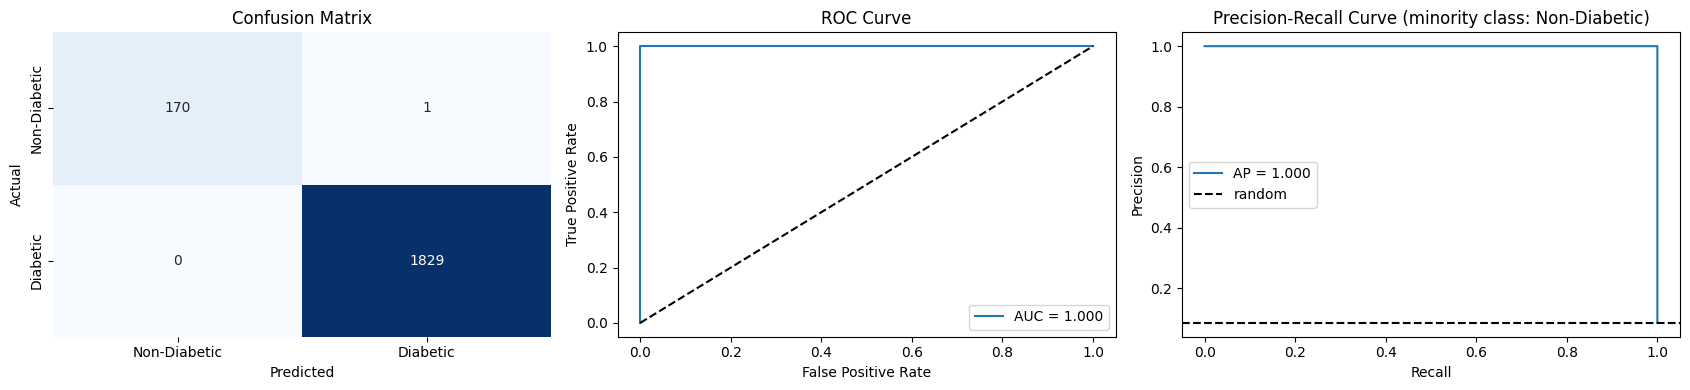

In [50]:
test_proba = best_model.predict_proba(X_test)[:, 1]
y_final = (test_proba >= best_thr).astype(int)

print("--- Classification Report (tuned threshold) ---")
print(classification_report(y_test, y_final, target_names=['Non-Diabetic', 'Diabetic'], zero_division=0))

roc_auc = roc_auc_score(y_test, test_proba)
pr_auc_diab = average_precision_score(y_test, test_proba)
pr_auc_non = average_precision_score(1 - y_test, 1 - test_proba)      # minority class (Non-Diabetic)
print("Accuracy:", round(accuracy_score(y_test, y_final), 4), "| Balanced accuracy:", round(balanced_accuracy_score(y_test, y_final), 4))
print("ROC-AUC:", round(roc_auc, 4), "| PR-AUC Diabetic:", round(pr_auc_diab, 4), "(random", round(y_test.mean(), 2), ") | PR-AUC Non-Diabetic:", round(pr_auc_non, 4), "(random", round(1 - y_test.mean(), 2), ")")

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
cm = confusion_matrix(y_test, y_final)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[0],
            xticklabels=['Non-Diabetic', 'Diabetic'], yticklabels=['Non-Diabetic', 'Diabetic'])
axes[0].set_title('Confusion Matrix'); axes[0].set_xlabel('Predicted'); axes[0].set_ylabel('Actual')

fpr, tpr, _ = roc_curve(y_test, test_proba)
axes[1].plot(fpr, tpr, label=f'AUC = {roc_auc:.3f}'); axes[1].plot([0, 1], [0, 1], 'k--')
axes[1].set_title('ROC Curve'); axes[1].set_xlabel('False Positive Rate'); axes[1].set_ylabel('True Positive Rate'); axes[1].legend()

p_, r_, _ = precision_recall_curve(1 - y_test, 1 - test_proba)
axes[2].plot(r_, p_, label=f'AP = {pr_auc_non:.3f}'); axes[2].axhline(1 - y_test.mean(), color='k', linestyle='--', label='random')
axes[2].set_title('Precision-Recall Curve (minority class: Non-Diabetic)'); axes[2].set_xlabel('Recall'); axes[2].set_ylabel('Precision'); axes[2].legend()
plt.tight_layout()
plt.show()

In [51]:
tn, fp, fn, tp = cm.ravel()
print("=== Automatic interpretation of the results ===")
print(f"- Model: {best_name} | threshold: {best_thr:.2f}")
print(f"- Diabetic patients: finds {tp} of {tp + fn} (recall = {tp / (tp + fn):.1%}), misses {fn}; precision = {tp / max(tp + fp, 1):.1%}.")
print(f"- Non-Diabetic (minority) patients: finds {tn} of {tn + fp} (recall = {tn / (tn + fp):.1%}), misses {fp}; precision = {tn / max(tn + fn, 1):.1%}.")
print(f"- Accuracy = {accuracy_score(y_test, y_final):.1%} (always saying 'Diabetic' would give {y_test.mean():.1%}); balanced accuracy = {balanced_accuracy_score(y_test, y_final):.1%}.")
print(f"- ROC-AUC = {roc_auc:.3f}.")

=== Automatic interpretation of the results ===
- Model: LightGBM | threshold: 0.97
- Diabetic patients: finds 1829 of 1829 (recall = 100.0%), misses 0; precision = 99.9%.
- Non-Diabetic (minority) patients: finds 170 of 171 (recall = 99.4%), misses 1; precision = 100.0%.
- Accuracy = 100.0% (always saying 'Diabetic' would give 91.5%); balanced accuracy = 99.7%.
- ROC-AUC = 1.000.


### Is the problem too easy? (check without HbA1c)
`HbA1c` is the medical test that **defines** diabetes (6.5% or more), and in this dataset all the Non-Diabetic patients have HbA1c <= 6.0. So the model can almost read the answer from one column. The next cell shows what happens without `HbA1c`.

In [52]:
no_hba1c = clone(tuned[best_name].best_estimator_).fit(X_train.drop(columns='HbA1c'), y_train)
p2 = no_hba1c.predict_proba(X_test.drop(columns='HbA1c'))[:, 1]
print(f"ROC-AUC with HbA1c    : {roc_auc:.4f}")
print(f"ROC-AUC without HbA1c : {roc_auc_score(y_test, p2):.4f}")

[LightGBM] [Info] Number of positive: 7317, number of negative: 683
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000212 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 690
[LightGBM] [Info] Number of data points in the train set: 8000, number of used features: 7
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.914625 -> initscore=2.371461
[LightGBM] [Info] Start training from score 2.371461
ROC-AUC with HbA1c    : 1.0000
ROC-AUC without HbA1c : 0.8777


**Interpretation**
- **Accuracy** must be compared with the 91% of the "always Diabetic" model; **balanced accuracy** and the **recall of the minority class (Non-Diabetic)** show if the model really separates both groups.
- **Confusion matrix:** FN = diabetic patients predicted healthy (the dangerous error in medicine), FP = healthy patients predicted diabetic (extra tests).
- **ROC-AUC** near 1 means the two groups are almost perfectly separable; **PR-AUC** is shown for the **minority class** because for the majority class it is high even for a random model.
- This is a binary problem, so no multiclass averaging is needed.
- **Limits:** the data looks synthetic and very clean (uniform ranges, a single column decides most of the answer), so these scores will not transfer to real patients. This is a learning project, not a medical tool; without `HbA1c` the performance is clearly lower.

## 13. Conclusions
- Missing values are filled with train-only statistics (no leakage); scaling, SMOTE and under-sampling use the train data only.
- The imbalance (91% / 9%) was handled with SMOTE / under-sampling / class weights and judged with balanced accuracy, minority-class recall, ROC-AUC and PR-AUC, not only Accuracy.
- The model was chosen with cross-validation, tuned with `GridSearchCV`, the threshold was chosen on training data, and the test set was used once.
- `HbA1c` almost decides the diagnosis; without it the task is much harder.
- The Gradio app below uses the final model and threshold.

## 14. Gradio app

In [53]:
import gradio as gr

def predict_diabetes(age, gender, blood_sugar, creatinine, bmi, urea, cholesterol, hba1c):
    gender_val = 0 if gender == "Female" else 1

    row = pd.DataFrame([[
        age, gender_val, blood_sugar, creatinine, bmi, urea, cholesterol, hba1c
    ]], columns=X.columns).astype(float)

    row[num_cols] = scaler.transform(row[num_cols])

    proba = best_model.predict_proba(row)[0, 1]
    answer = "Diabetic (مريض سكري)" if proba >= best_thr else "Non-Diabetic (سليم)"
    return f"{answer}  -  probability of diabetes = {proba:.0%}"

demo = gr.Interface(
    fn=predict_diabetes,
    inputs=[
        gr.Number(label="Age", value=45),
        gr.Dropdown(["Female", "Male"], label="Gender", value="Female"),
        gr.Number(label="Blood Sugar Level", value=110),
        gr.Number(label="Creatinine", value=1.0),
        gr.Number(label="BMI", value=25.0),
        gr.Number(label="Urea", value=30.0),
        gr.Number(label="Cholesterol", value=200.0),
        gr.Number(label="HbA1c", value=5.5),
    ],
    outputs=gr.Textbox(label="Prediction Result"),
    title="Diabetes Prediction App",
    description="Enter patient medical details to predict whether the patient has diabetes.",
)

demo.launch(share=True)   # share=True gives a public link when you run it in Colab

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://90a7a20417e11a5be6.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
